In [2]:
# Q10: House Price Prediction Using Linear Regression

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
# 2. Load dataset
df = pd.read_csv("House Price Prediction Dataset.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.isnull().sum())
print(df.describe())

Dataset Shape: (2000, 10)
   Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location  Condition  \
0   1  1360         5          4       3       1970  Downtown  Excellent   
1   2  4272         5          4       3       1958  Downtown  Excellent   
2   3  3592         2          2       3       1938  Downtown       Good   
3   4   966         4          2       2       1902  Suburban       Fair   
4   5  4926         1          4       2       1975  Downtown       Fair   

  Garage   Price  
0     No  149919  
1     No  424998  
2     No  266746  
3    Yes  244020  
4    Yes  636056  
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64
                Id         Area     Bedrooms   Bathrooms       Floors  \
count  2000.000000  2000.000000  2000.000000  2000.00000  2000.000000   
mean   1000.500000  2786.209500     3.003500     2.55250     1.993500   
std     577.494589  1

In [13]:
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


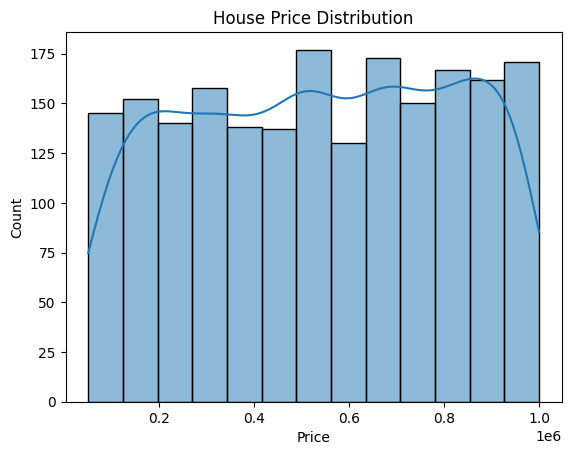

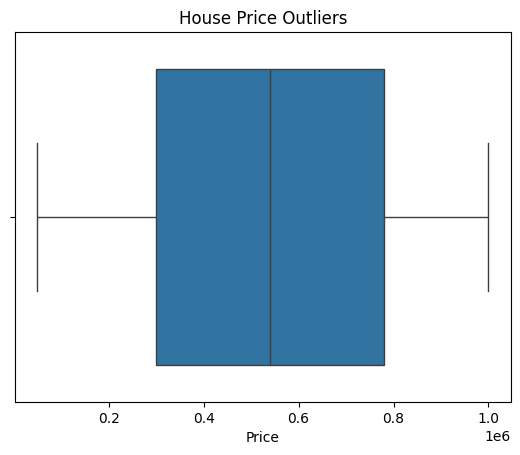

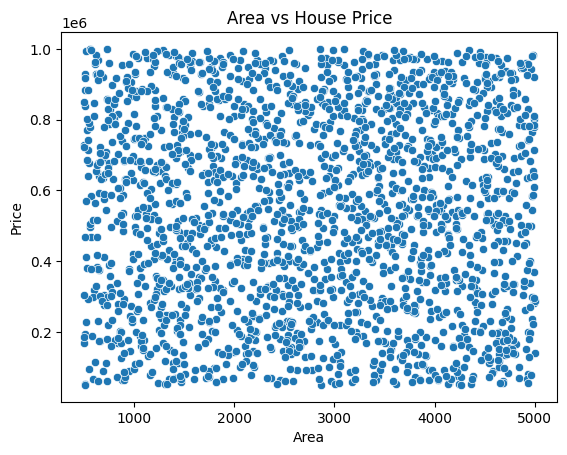

In [4]:
# 3. EDA
sns.histplot(df["Price"], kde=True)
plt.title("House Price Distribution")
plt.show()

sns.boxplot(x=df["Price"])
plt.title("House Price Outliers")
plt.show()

sns.scatterplot(x=df["Area"], y=df["Price"])
plt.title("Area vs House Price")
plt.show()


In [17]:
# 4. Prepare features and target
X = df.drop(columns=["Price", "Id"], errors="ignore")
y = df["Price"]

# Handle missing values
X = X.fillna(X.median(numeric_only=True))
X = X.fillna(X.mode().iloc[0])

# Encode categorical features
X = pd.get_dummies(X, drop_first=True,dtype=int)

In [18]:
X

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1360,5,4,3,1970,0,0,0,0,0,0,0
1,4272,5,4,3,1958,0,0,0,0,0,0,0
2,3592,2,2,3,1938,0,0,0,0,1,0,0
3,966,4,2,2,1902,0,1,0,1,0,0,1
4,4926,1,4,2,1975,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1995,4994,5,4,3,1923,0,1,0,0,0,1,0
1996,3046,5,2,1,2019,0,1,0,0,0,1,1
1997,1062,5,1,2,1903,1,0,0,0,0,1,0
1998,4062,3,1,2,1936,0,0,1,0,0,0,1


In [19]:
X.dtypes

Area                 int64
Bedrooms             int64
Bathrooms            int64
Floors               int64
YearBuilt            int64
Location_Rural       int64
Location_Suburban    int64
Location_Urban       int64
Condition_Fair       int64
Condition_Good       int64
Condition_Poor       int64
Garage_Yes           int64
dtype: object

In [20]:
# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)


Training Features: (1600, 12)
Testing Features: (400, 12)


In [21]:
# 6. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)



,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
# 7. Predict house prices
y_pred = model.predict(X_test)
print("Predicted Prices:")
print(y_pred[:10])



Predicted Prices:
[521988.22189839 549119.31196651 487101.22235594 539752.7439933
 553242.24872512 521375.92025826 523320.18080583 578133.64353335
 545899.64738458 577368.69940644]


In [23]:
# 8. Evaluate model
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))

R2 Score: -0.006717808430749761
RMSE: 279859.72583784326
MAE: 243241.97758826384


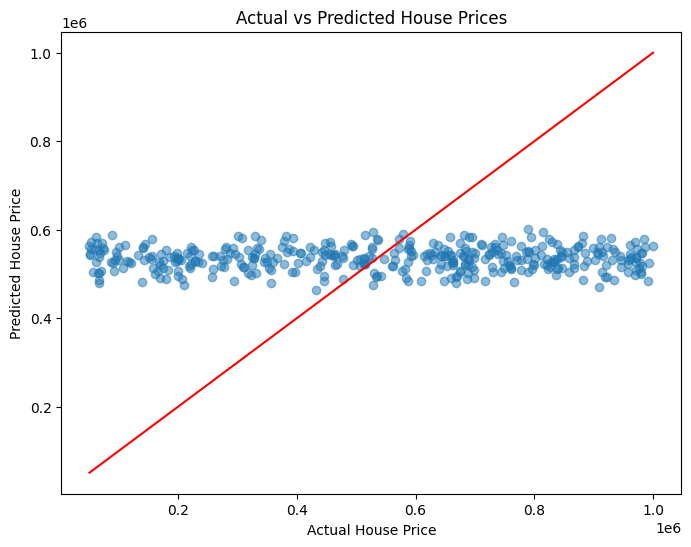

In [24]:
# 9. Actual vs Predicted plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.show()